# Training multitask arsitektur.py (deteksi + depth) - RTX 4050

Notebook memakai build_model() dari arsitektur.py dan train_arsitektur.py. Arsitektur custom, nama/bentuk output P3/P4/P5 dan depth dipertahankan; notebook ini tidak mengganti model dengan DetectionModel Ultralytics.

- SUN RGB-D dan data COCO lokal yang terpilih masing-masing dibagi 70% train, 20% validation, 10% test. SUN dikelompokkan per scene; COCO per gambar.
- Split dibuat deterministik di memori (seed 42); file dataset tidak dipindahkan atau disalin.
- Backbone/neck dapat diinisialisasi dari yolo26n.pt untuk run baru. Jika last.pt cocok ditemukan, notebook melanjutkan checkpoint proyek itu.
- Checkpoint disimpan atomik oleh trainer; notebook membuat backup timestamp last.pt/best.pt sebelum resume.
- Training tidak dimulai sampai CONFIRM_TRAIN = True secara eksplisit.

Trainer mendukung resume bobot, optimizer, scheduler, EMA, dan metrik terbaik; checkpoint belum memulihkan GradScaler, RNG, atau riwayat epoch penuh. Trainer juga belum menyediakan early stopping. Perubahan split tidak mengubah arsitektur.py maupun kontrak output model.

In [16]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import torch

ROOT = Path(r"C:\Users\ACER\Downloads\Comvis\code")
if not (ROOT / "train_arsitektur.py").is_file():
    ROOT = Path.cwd().resolve()
if not (ROOT / "train_arsitektur.py").is_file() or not (ROOT / "arsitektur.py").is_file():
    raise FileNotFoundError("Buka notebook dari folder proyek yang berisi train_arsitektur.py dan arsitektur.py.")

DATASET_ROOT = ROOT / "datasets"
SUN_ROOT = DATASET_ROOT / "SUNRGBD" / "SUNRGBD"
COCO_ROOT = DATASET_ROOT / "coco"
COCO_ANNOTATIONS = COCO_ROOT / "annotations" / "instances_train2017.json"
if not SUN_ROOT.is_dir():
    raise FileNotFoundError(f"Folder SUN RGB-D tidak ditemukan: {SUN_ROOT}")
if not COCO_ANNOTATIONS.is_file():
    raise FileNotFoundError(f"Anotasi COCO train tidak ditemukan: {COCO_ANNOTATIONS}")

print("Project:", ROOT)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
if not torch.cuda.is_available():
    print("PyTorch CUDA build:", torch.version.cuda)
    raise RuntimeError(
        "CUDA tidak tersedia pada kernel ini. GPU NVIDIA mungkin terlihat oleh Windows, "
        "tetapi environment notebook memakai PyTorch CPU-only atau build CUDA yang tidak cocok. "
        "Pasang build PyTorch CUDA yang sesuai melalui https://pytorch.org/get-started/locally/, "
        "restart kernel, lalu jalankan ulang sel ini sebelum training."
    )
GPU = torch.cuda.get_device_name(0)
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3
print(f"GPU: {GPU} ({VRAM_GB:.1f} GiB VRAM)")
IMAGE_DIR = COCO_ROOT / "train2017" if (COCO_ROOT / "train2017").is_dir() else COCO_ROOT
COCO_IMAGE_COUNT = sum(1 for path in IMAGE_DIR.glob("*.jpg") if path.is_file())
print("SUN RGB-D root:", SUN_ROOT)
print("COCO images available locally:", COCO_IMAGE_COUNT)
print("COCO annotations:", COCO_ANNOTATIONS)

Project: C:\Users\ACER\Downloads\Comvis\code
Python: c:\Users\ACER\AppData\Local\Programs\Python\Python310\python.exe
PyTorch: 2.5.1+cu121
GPU: NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GiB VRAM)
SUN RGB-D root: C:\Users\ACER\Downloads\Comvis\code\datasets\SUNRGBD\SUNRGBD
COCO images available locally: 749
COCO annotations: C:\Users\ACER\Downloads\Comvis\code\datasets\coco\annotations\instances_train2017.json


In [17]:
missing_packages = []
if importlib.util.find_spec("ijson") is None:
    missing_packages.append("ijson")
if importlib.util.find_spec("ultralytics") is None:
    missing_packages.append("ultralytics==8.4.175")
if missing_packages:
    print("Installing training dependencies:", missing_packages)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

import ijson
from ultralytics import YOLO
print("Streaming JSON parser:", ijson.__version__)
print("Ultralytics:", YOLO.__module__)

Streaming JSON parser: 3.6.0
Ultralytics: ultralytics.models.yolo.model


## Konfigurasi training dan evaluasi

SUN RGB-D dibagi per scene/group dan COCO per gambar, masing-masing menjadi train, validation, dan test (70% / 20% / 10%). Group SUN yang sama tidak boleh bocor antar-split. COCO_RATIO tetap mengatur target porsi COCO di split training; hanya gambar COCO lokal yang memiliki anotasi kelas target yang dipakai. Evaluasi COCO memakai held-out dari instances_train2017 lokal, bukan benchmark resmi COCO val/test. Metrik depth hanya memakai piksel SUN RGB-D yang valid.

Pada komputer ini RTX 4050 Laptop memiliki sekitar 6 GiB VRAM. Konfigurasi awal memakai batch 4, AMP, dan dua DataLoader workers Windows; smoke forward memakai batch 1. Bila terjadi OOM, turunkan BATCH_SIZE (mis. 2) dan jalankan lagi.

Checkpoint lama akan dilanjutkan otomatis hanya melalui resume trainer, yang memvalidasi arsitektur, kelas, ukuran gambar, batas depth, dan split. Checkpoint menyimpan model, optimizer, scheduler, EMA dan metrik; implementasi sekarang tidak menyimpan/memulihkan scaler AMP, RNG, atau seluruh history. Tidak ada early stopping pada trainer saat ini. Notebook merekam log dan metrik epoch baru agar run dapat diaudit tanpa mengubah loop training.

Dataset yang digunakan hanya dari path lokal. Perintah trainer memasang --no-download dan --coco-local-only; bila data/anotasi tidak lengkap, proses gagal dengan pesan jelas, bukan mengunduh dataset.

In [ ]:
CLASSES = ("person", "laptop", "cell phone", "bottle")
IMAGE_SIZE = (384, 640)  # H, W; multiples of 32 required by arsitektur.py
DEPTH_MAX_M = 10.0

EPOCHS = 100
BATCH_SIZE = 4 if VRAM_GB < 8 else 8  # RTX 4050 Laptop: start conservatively at 4
NUM_WORKERS = 2  # Windows DataLoader; use 0 if multiprocessing is unstable
COCO_RATIO = 0.5  # Target proporsi COCO di split training, bukan fraksi split.
SEED = 42
VAL_FRACTION = 0.2
TEST_FRACTION = 0.1

LEARNING_RATE = 1e-3
BACKBONE_LR_MULT = 0.1
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 3.0
MIN_LR_RATIO = 0.02
EMA_DECAY = 0.999

CLS_WEIGHT = 1.0
BOX_WEIGHT = 7.5
DEPTH_WEIGHT = 0.5
FOCAL_ALPHA = 0.25
FOCAL_GAMMA = 2.0
TOPK_ASSIGN = 3

SCALE_JITTER = 0.2
TRANSLATE_JITTER = 0.08
HSV_JITTER = 1.0

BALANCED_SAMPLING = True
BALANCE_THRESHOLD = 0.25
BALANCE_CAP = 8.0
DEPTH_ONLY_WEIGHT = 0.3

CONF_THRESHOLD = 0.001
NMS_IOU = 0.7
MAX_DETECTIONS = 300
BEST_METRIC = "map50"

SMOKE_TEST = False
CONFIRM_TRAIN = True

  # Training tetap opt-in secara eksplisit.
RESUME_MODE = "auto"  # Keep this run resumable; do not overwrite it with a fresh run.
EXPORT_ONNX = False  # Optional raw-output export; requires the onnx Python package.
PRETRAINED_WEIGHTS = ROOT / "yolo26n.pt"
RUN_NAME = "rtx4050_arsitektur_smoke_70_20_10" if SMOKE_TEST else "rtx4050_arsitektur_70_20_10"
RUN_DIR = ROOT / "training_runs" / "persist" / RUN_NAME
BEST_CHECKPOINT = RUN_DIR / "best.pt"
LAST_CHECKPOINT = RUN_DIR / "last.pt"
EVALUATION_REPORT = RUN_DIR / "evaluation.json"
HISTORY_CSV = RUN_DIR / "history.csv"
if not PRETRAINED_WEIGHTS.is_file():
    raise FileNotFoundError(f"Bobot pretrained tidak ditemukan: {PRETRAINED_WEIGHTS}")
if RESUME_MODE != "auto":
    raise ValueError("Only RESUME_MODE='auto' is supported here to protect existing run artifacts.")
RESUME_CHECKPOINT = LAST_CHECKPOINT if LAST_CHECKPOINT.is_file() else None
print({
    "classes": CLASSES,
    "image_size": IMAGE_SIZE,
    "split_each_dataset": {"train": 1 - VAL_FRACTION - TEST_FRACTION,
                           "validation": VAL_FRACTION, "test": TEST_FRACTION},
    "sun_rgbd_grouped_by_scene": True,
    "coco": "local annotated images split independently by image; downloads disabled",
    "epochs": 1 if SMOKE_TEST else EPOCHS,
    "batch_size": BATCH_SIZE,
    "workers": NUM_WORKERS,
    "amp": True,
    "learning_rate": LEARNING_RATE,
    "backbone_lr_mult": BACKBONE_LR_MULT,
    "warmup_epochs": WARMUP_EPOCHS,
    "loss_weights": {"cls": CLS_WEIGHT, "box": BOX_WEIGHT, "depth": DEPTH_WEIGHT},
    "topk_assign": TOPK_ASSIGN,
    "augmentation": {"scale": SCALE_JITTER, "translate": TRANSLATE_JITTER, "hsv": HSV_JITTER},
    "balanced_sampling": BALANCED_SAMPLING,
    "coco_ratio": COCO_RATIO,
    "best_metric": BEST_METRIC,
    "resume_checkpoint": str(RESUME_CHECKPOINT) if RESUME_CHECKPOINT else "fresh run",
    "initial_weights": str(PRETRAINED_WEIGHTS),
    "output": str(RUN_DIR),
    "training_armed": CONFIRM_TRAIN,
})

{'classes': ('person', 'laptop', 'cell phone', 'bottle'), 'image_size': (384, 640), 'split_each_dataset': {'train': 0.7000000000000001, 'validation': 0.2, 'test': 0.1}, 'sun_rgbd_grouped_by_scene': True, 'coco': 'local annotated images split independently by image; downloads disabled', 'epochs': 100, 'batch_size': 4, 'workers': 2, 'amp': True, 'learning_rate': 0.001, 'backbone_lr_mult': 0.1, 'warmup_epochs': 3.0, 'loss_weights': {'cls': 1.0, 'box': 7.5, 'depth': 0.5}, 'topk_assign': 3, 'augmentation': {'scale': 0.2, 'translate': 0.08, 'hsv': 1.0}, 'balanced_sampling': True, 'coco_ratio': 0.5, 'best_metric': 'map50', 'resume_checkpoint': 'fresh run', 'initial_weights': 'C:\\Users\\ACER\\Downloads\\Comvis\\code\\yolo26n.pt', 'output': 'C:\\Users\\ACER\\Downloads\\Comvis\\code\\training_runs\\persist\\rtx4050_arsitektur_70_20_10', 'training_armed': True}


## Statistik dataset dan keseimbangan kelas

Sel ini memindai anotasi SUN RGB-D untuk melihat berapa banyak box per kelas sebelum training. Ini penting karena kelas `cell phone` sangat langka di SUN RGB-D dan sebagian besar scene hanya punya label depth.

In [19]:
import collections
import sys as _sys

if str(ROOT) not in _sys.path:
    _sys.path.insert(0, str(ROOT))
import train_arsitektur as trainer

sun_records = trainer.discover_sun_records(SUN_ROOT, CLASSES, DEPTH_MAX_M, "auto")
class_boxes = collections.Counter()
class_images = collections.Counter()
for record in sun_records:
    ids = [int(box[4]) for box in record.boxes]
    for class_id in set(ids):
        class_images[class_id] += 1
    for class_id in ids:
        class_boxes[class_id] += 1

# Recreate the trainer's deterministic group split for a read-only leakage audit.
audit_train, audit_val, audit_test = trainer.split_sun_records(
    sun_records, VAL_FRACTION, TEST_FRACTION, SEED
)
group_sets = [
    {record.group for record in split}
    for split in (audit_train, audit_val, audit_test)
]
if (group_sets[0] & group_sets[1]) or (group_sets[0] & group_sets[2]) or (group_sets[1] & group_sets[2]):
    raise AssertionError("SUN RGB-D scene/group leakage detected between splits.")
print("Split leakage audit: PASS (SUN RGB-D scene groups are disjoint)")
print(f"  target ratio per dataset: {1 - VAL_FRACTION - TEST_FRACTION:.0%}/{VAL_FRACTION:.0%}/{TEST_FRACTION:.0%}")
print(f"  SUN records train/val/test: {len(audit_train)}/{len(audit_val)}/{len(audit_test)}")
print(f"  groups train/val/test: {len(group_sets[0])}/{len(group_sets[1])}/{len(group_sets[2])}")

records_with_boxes = sum(1 for record in sun_records if record.boxes)
print(f"\nSUN RGB-D: {len(sun_records)} scene total")
print(f"  scene dengan box kelas target : {records_with_boxes}")
print(f"  scene hanya label depth       : {len(sun_records) - records_with_boxes}")
print(f"\n{'Kelas':<14}{'Box':>8}{'Gambar':>10}{'Rasio box':>12}")
total_boxes = sum(class_boxes.values())
for class_id, name in enumerate(CLASSES):
    share = class_boxes[class_id] / total_boxes * 100 if total_boxes else 0.0
    print(f"{name:<14}{class_boxes[class_id]:>8}{class_images[class_id]:>10}{share:>11.1f}%")
print(f"\nCOCO lokal tersedia: {COCO_IMAGE_COUNT} gambar (sumber utama untuk 'cell phone' dan 'person')")
print("Kelas langka akan di-oversampling lewat --balanced-sampling.")

SUN RGB-D depth rotation: on; object index base: 0
Skipping SUN RGB-D scene with invalid annotation: Could not read SUN RGB-D annotation C:\Users\ACER\Downloads\Comvis\code\datasets\SUNRGBD\SUNRGBD\kv1\b3dodata\img_0139\annotation2Dfinal\index.json
Skipping SUN RGB-D scene with invalid annotation: Could not read SUN RGB-D annotation C:\Users\ACER\Downloads\Comvis\code\datasets\SUNRGBD\SUNRGBD\kv1\b3dodata\img_0174\annotation2Dfinal\index.json
Found 2001 SUN RGB-D records; depth rotation enabled.
Split leakage audit: PASS (SUN RGB-D scene groups are disjoint)
  target ratio per dataset: 70%/20%/10%
  SUN records train/val/test: 1398/403/200
  groups train/val/test: 17/5/2

SUN RGB-D: 2001 scene total
  scene dengan box kelas target : 531
  scene hanya label depth       : 1470

Kelas              Box    Gambar   Rasio box
person             132        81       11.0%
laptop              78        74        6.5%
cell phone           2         2        0.2%
bottle             987       419 

## Smoke test arsitektur

Sel ini hanya forward pass satu batch kecil untuk memastikan output deteksi P3/P4/P5 dan peta depth terbentuk. Belum memulai training.

In [20]:
from arsitektur import ARCHITECTURE_ID, build_model

DEVICE = torch.device("cuda")
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
model = build_model(num_classes=len(CLASSES)).to(DEVICE).eval()
with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16):
    sample = torch.zeros((1, 3, *IMAGE_SIZE), device=DEVICE)
    outputs = model(sample, use_nms=False)
torch.cuda.synchronize()
print("Architecture:", ARCHITECTURE_ID)
for key in ("p3_bbox", "p3_cls", "p4_bbox", "p4_cls", "p5_bbox", "p5_cls", "depth"):
    print(f"{key}: {tuple(outputs[key].shape)}")
assert outputs["depth"].shape == (1, 1, *IMAGE_SIZE)
assert all(key in outputs for key in ("p3_bbox", "p3_cls", "p4_bbox", "p4_cls", "p5_bbox", "p5_cls", "depth"))
total_parameters = sum(parameter.numel() for parameter in model.parameters())
peak_gib = torch.cuda.max_memory_allocated() / 1024**3
print(f"Parameter: {total_parameters / 1e6:.2f} M; AMP smoke peak: {peak_gib:.2f} GiB")
del model, sample, outputs
torch.cuda.empty_cache()

Architecture: ultralytics-yolo26n-backbone-neck-project-heads-v2
p3_bbox: (1, 4, 48, 80)
p3_cls: (1, 4, 48, 80)
p4_bbox: (1, 4, 24, 40)
p4_cls: (1, 4, 24, 40)
p5_bbox: (1, 4, 12, 20)
p5_cls: (1, 4, 12, 20)
depth: (1, 1, 384, 640)
Parameter: 3.86 M; AMP smoke peak: 0.33 GiB


## Jalankan training, resume, dan evaluasi test

Notebook tetap memakai model dari build_model() di arsitektur.py dan CLI trainer train_arsitektur.py. Resume otomatis menggunakan last.pt bila tersedia dan trainer memeriksa identitas arsitektur, kelas, ukuran gambar, konfigurasi depth, serta seed/fraction split sebelum memuatnya. Resume tidak mengirim --pretrained-yolo26 sekaligus, karena kedua opsi memang saling eksklusif.

Trainer menulis last.pt dan best.pt secara atomik. Notebook menyalin checkpoint lama ke checkpoint_backups dengan timestamp sebelum proses yang mungkin menggantinya. Training log lengkap ditulis ke berkas unik; keluaran notebook hanya menampilkan ringkasan epoch/peristiwa penting, sedangkan history.csv menyimpan metrik epoch yang teramati. Untuk checkpoint lama, history hanya dapat dimulai dari metrik epoch checkpoint tersebut; epoch yang tidak pernah dicatat tidak direka ulang.

Validasi per epoch mengukur loss, depth MAE, mAP@0.5, mAP@0.5:0.95, precision, dan recall. Checkpoint terbaik dipilih berdasarkan BEST_METRIC yang tersedia. Setelah training selesai, trainer mengevaluasi test split sekali dan menulis evaluation.json. Implementasi trainer belum mendukung early stopping atau restore GradScaler/RNG; resume mempertahankan model, optimizer, scheduler, dan EMA, tetapi tidak menjamin kelanjutan bit-identik.

Pastikan preflight CUDA, audit split, dan statistik data sudah lolos. Training hanya berjalan setelah CONFIRM_TRAIN = True; perintah selalu memakai --no-download dan --coco-local-only. Folder run 70/20/10 terpisah dari checkpoint eksperimen lama, sehingga checkpoint lama tetap utuh dan tidak di-resume dengan split baru.

In [21]:
if not CONFIRM_TRAIN:
    print("Training belum dijalankan. Periksa CUDA, audit split, konfigurasi, dan statistik data; set CONFIRM_TRAIN = True secara eksplisit untuk melanjutkan.")
else:
    import csv
    import datetime
    import os
    import re
    import shutil
    import subprocess
    import uuid

    RUN_DIR.mkdir(parents=True, exist_ok=True)
    resume_checkpoint = LAST_CHECKPOINT if LAST_CHECKPOINT.is_file() else None
    stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    checkpoint_files = [path for path in (LAST_CHECKPOINT, BEST_CHECKPOINT) if path.is_file()]
    if checkpoint_files:
        backup_bytes = sum(path.stat().st_size for path in checkpoint_files)
        if shutil.disk_usage(RUN_DIR).free < backup_bytes + 64 * 1024**2:
            raise OSError("Ruang disk tidak cukup untuk membackup checkpoint lama; tidak memulai training.")
        backup_dir = RUN_DIR / "checkpoint_backups"
        backup_dir.mkdir(parents=True, exist_ok=True)
        for checkpoint_path in checkpoint_files:
            backup_path = backup_dir / f"{checkpoint_path.stem}.before_{stamp}_{uuid.uuid4().hex[:8]}.pt"
            shutil.copy2(checkpoint_path, backup_path)
            print("Checkpoint backup:", backup_path)

    log_path = RUN_DIR / f"training_{stamp}.log"
    history_exists = HISTORY_CSV.is_file()
    history_columns = [
        "epoch", "train_loss", "val_loss", "val_classification", "val_box",
        "val_depth", "val_depth_mae_m", "val_map50", "val_map50_95",
        "val_precision", "val_recall", "learning_rate",
    ]
    if not history_exists:
        with HISTORY_CSV.open("w", newline="", encoding="utf-8") as history_file:
            csv.DictWriter(history_file, fieldnames=history_columns).writeheader()
    recorded_epochs = set()
    with HISTORY_CSV.open("r", newline="", encoding="utf-8") as history_file:
        recorded_epochs = {int(row["epoch"]) for row in csv.DictReader(history_file) if row.get("epoch")}

    if resume_checkpoint is not None and not recorded_epochs:
        previous = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
        train_metrics = previous.get("train_metrics", {})
        val_metrics = previous.get("val_metrics", {})
        if isinstance(train_metrics, dict) and isinstance(val_metrics, dict) and previous.get("epoch"):
            baseline = {
                "epoch": int(previous["epoch"]),
                "train_loss": train_metrics.get("loss", ""),
                "val_loss": val_metrics.get("loss", ""),
                "val_classification": val_metrics.get("classification", ""),
                "val_box": val_metrics.get("box", ""),
                "val_depth": val_metrics.get("depth", ""),
                "val_depth_mae_m": previous.get("val_depth_mae_m", ""),
                "val_map50": val_metrics.get("map50", ""),
                "val_map50_95": val_metrics.get("map50_95", ""),
                "val_precision": val_metrics.get("precision", ""),
                "val_recall": val_metrics.get("recall", ""),
                "learning_rate": "",
            }
            with HISTORY_CSV.open("a", newline="", encoding="utf-8") as history_file:
                csv.DictWriter(history_file, fieldnames=history_columns).writerow(baseline)
            recorded_epochs.add(int(previous["epoch"]))
            print("History starts from checkpoint epoch", previous["epoch"], "(older epoch logs were not present).")

    command = [
        sys.executable, "-u", str(ROOT / "train_arsitektur.py"),
        "--sun-root", str(SUN_ROOT),
        "--coco-root", str(COCO_ROOT),
        "--coco-annotations", str(COCO_ANNOTATIONS),
        "--download-dir", str(DATASET_ROOT),
        "--output-dir", str(RUN_DIR),
        "--classes", *CLASSES,
        "--img-size", str(IMAGE_SIZE[0]), str(IMAGE_SIZE[1]),
        "--depth-max-m", str(DEPTH_MAX_M),
        "--epochs", str(1 if SMOKE_TEST else EPOCHS),
        "--batch-size", str(BATCH_SIZE),
        "--workers", str(NUM_WORKERS),
        "--coco-ratio", str(COCO_RATIO),
        "--val-fraction", str(VAL_FRACTION),
        "--test-fraction", str(TEST_FRACTION),
        "--learning-rate", str(LEARNING_RATE),
        "--backbone-lr-mult", str(BACKBONE_LR_MULT),
        "--weight-decay", str(WEIGHT_DECAY),
        "--warmup-epochs", str(WARMUP_EPOCHS),
        "--min-lr-ratio", str(MIN_LR_RATIO),
        "--ema-decay", str(EMA_DECAY),
        "--cls-weight", str(CLS_WEIGHT),
        "--box-weight", str(BOX_WEIGHT),
        "--depth-weight", str(DEPTH_WEIGHT),
        "--focal-alpha", str(FOCAL_ALPHA),
        "--focal-gamma", str(FOCAL_GAMMA),
        "--topk-assign", str(TOPK_ASSIGN),
        "--scale-jitter", str(SCALE_JITTER),
        "--translate-jitter", str(TRANSLATE_JITTER),
        "--hsv-jitter", str(HSV_JITTER),
        "--balanced-sampling",
        "--balance-threshold", str(BALANCE_THRESHOLD),
        "--balance-cap", str(BALANCE_CAP),
        "--depth-only-weight", str(DEPTH_ONLY_WEIGHT),
        "--conf-threshold", str(CONF_THRESHOLD),
        "--nms-iou", str(NMS_IOU),
        "--max-detections", str(MAX_DETECTIONS),
        "--best-metric", BEST_METRIC,
        "--seed", str(SEED),
        "--device", "cuda",
        "--amp",
        "--no-download",
        "--coco-local-only",
    ]
    if resume_checkpoint is not None:
        command += ["--resume", str(resume_checkpoint)]
    else:
        command += ["--pretrained-yolo26", str(PRETRAINED_WEIGHTS)]
    if SMOKE_TEST:
        command += [
            "--max-train-samples", "200",
            "--max-val-samples", "40",
            "--max-test-samples", "40",
            "--warmup-epochs", "0",
        ]

    print("GPU:", GPU, f"({VRAM_GB:.1f} GiB); batch={BATCH_SIZE}; AMP=True")
    print("Resume:", resume_checkpoint if resume_checkpoint else "fresh run from local yolo26n.pt weights")
    print("Full process log:", log_path)
    print("Epoch history:", HISTORY_CSV)
    process = subprocess.Popen(
        command,
        cwd=ROOT,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
        encoding="utf-8",
        errors="replace",
    )
    assert process.stdout is not None
    epoch_pattern = re.compile(r"\bEpoch\s+(\d+)/(\d+)\s+train_loss=")
    metric_pattern = re.compile(r"([A-Za-z0-9_]+)=([0-9.eE+-]+)")
    important_pattern = re.compile(
        r"Epoch\s+\d+/\d+\s+train_loss=|Saved best checkpoint:|Resuming after epoch|"
        r"Split \d+ COCO images|Split sizes |Test metrics |Evaluation report:|Training complete\.|"
        r"Traceback|RuntimeError|ValueError|FileNotFoundError|FloatingPointError"
    )
    field_map = {
        "train_loss": "train_loss", "val_loss": "val_loss",
        "val_classification": "val_det_cls", "val_box": "val_box",
        "val_depth": "val_depth", "val_depth_mae_m": "val_depth_MAE_m",
        "val_map50": "val_mAP50", "val_map50_95": "val_mAP50_95",
        "val_precision": "val_P", "val_recall": "val_R",
        "learning_rate": "lr",
    }
    with log_path.open("w", encoding="utf-8") as log_file:
        for raw_line in process.stdout:
            log_file.write(raw_line)
            log_file.flush()
            for output_line in raw_line.rstrip("\n").split("\r"):
                clean_line = re.sub(r"\x1b\[[0-?]*[ -/]*[@-~]", "", output_line).strip()
                if not clean_line:
                    continue
                epoch_match = epoch_pattern.search(clean_line)
                if epoch_match:
                    epoch_number = int(epoch_match.group(1))
                    values = dict(metric_pattern.findall(clean_line))
                    if epoch_number not in recorded_epochs:
                        row = {column: "" for column in history_columns}
                        row["epoch"] = epoch_number
                        for column, output_key in field_map.items():
                            row[column] = values.get(output_key, "")
                        with HISTORY_CSV.open("a", newline="", encoding="utf-8") as history_file:
                            csv.DictWriter(history_file, fieldnames=history_columns).writerow(row)
                        recorded_epochs.add(epoch_number)
                if important_pattern.search(clean_line):
                    print(clean_line, flush=True)
    return_code = process.wait()
    if return_code != 0:
        raise subprocess.CalledProcessError(return_code, command)
    print("Training process completed successfully.")
    print("Evaluation report:", EVALUATION_REPORT)

GPU: NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GiB); batch=4; AMP=True
Resume: fresh run from local yolo26n.pt weights
Full process log: C:\Users\ACER\Downloads\Comvis\code\training_runs\persist\rtx4050_arsitektur_70_20_10\training_20261023_042459_744682.log
Epoch history: C:\Users\ACER\Downloads\Comvis\code\training_runs\persist\rtx4050_arsitektur_70_20_10\history.csv
Split 749 COCO images into train/validation/test=524/150/75 (target COCO share of training data 50%).
Split sizes train=1922 (SUN RGB-D=1398, COCO=524) | validation=553 (SUN RGB-D=403, COCO=150) | test=275 (SUN RGB-D=200, COCO=75)
Epoch 1/100 train_loss=1.3435 val_loss=0.3747 val_det_cls=0.0052 val_box=0.0465 val_depth=0.0409 val_depth_MAE_m=0.771 val_mAP50=0.0919 val_mAP50_95=0.0364 val_P=0.0021 val_R=0.3618 lr=3.34e-04 vram_peak=1.58GiB vram_free=3.11GiB
Saved best checkpoint: C:\Users\ACER\Downloads\Comvis\code\training_runs\persist\rtx4050_arsitektur_70_20_10\best.pt
Epoch 2/100 train_loss=0.4420 val_loss=0.3054 val_de

## Hasil split, metrik deteksi, dan depth

Sel ini membaca evaluation.json yang dibuat trainer. Metrik deteksi (mAP@0.5, mAP@0.5:0.95, precision, recall) dihitung di split test held-out SUN RGB-D + subset lokal COCO instances_train2017 dengan NMS per kelas; hasil COCO ini bukan benchmark val/test resmi. Depth MAE diukur dalam meter hanya pada piksel depth valid SUN RGB-D. COCO tidak punya label depth sehingga tidak berkontribusi ke depth MAE.

In [22]:
import json

if EVALUATION_REPORT.is_file():
    report = json.loads(EVALUATION_REPORT.read_text(encoding="utf-8"))
    print("Jumlah data per split (record/gambar):")
    print(f"{'Split':<12} {'SUN RGB-D':>12} {'COCO':>8} {'Total':>8}")
    for split_name in ("train", "validation", "test"):
        split = report["splits"][split_name]
        print(
            f"{split_name:<12} {split['sun_rgbd_records']:>12} "
            f"{split['coco_records']:>8} {split['total_records']:>8}"
        )
        print(f"  kotak per kelas: {split['boxes_by_class']}")

    metrics = report["test_metrics"]
    best_metrics = report["best_epoch_metrics"]
    metric_rows = (
        ("train", best_metrics["train"], "-"),
        ("validation", best_metrics["validation"], f"{best_metrics['validation_depth_mae_m']:.3f}"),
        ("test", metrics, f"{metrics['depth_mae_m']:.3f}"),
    )
    print("\nMetrik loss dan depth MAE pada epoch checkpoint terbaik:")
    print(
        f"{'Split':<12} {'Total loss':>12} {'Cls loss':>12} "
        f"{'Box loss':>12} {'Depth loss':>12} {'Depth MAE (m)':>15}"
    )
    for split_name, values, depth_mae in metric_rows:
        print(
            f"{split_name:<12} {values['loss']:>12.4f} "
            f"{values['classification']:>12.4f} {values['box']:>12.4f} "
            f"{values['depth']:>12.4f} {depth_mae:>15}"
        )

    print("\nMetrik deteksi (mAP dihitung dengan NMS per kelas):")
    print(
        f"{'Split':<12} {'mAP@0.5':>10} {'mAP@0.5:0.95':>14} "
        f"{'Precision':>10} {'Recall':>10}"
    )
    for split_name, values in (("validation", best_metrics["validation"]), ("test", metrics)):
        print(
            f"{split_name:<12} {values.get('map50', 0.0):>10.4f} "
            f"{values.get('map50_95', 0.0):>14.4f} "
            f"{values.get('precision', 0.0):>10.4f} "
            f"{values.get('recall', 0.0):>10.4f}"
        )

    per_class = metrics.get("per_class_ap50", {})
    if per_class:
        print("\nAP@0.5 per kelas pada split test:")
        for class_name, value in per_class.items():
            print(f"  {class_name:<14}{value:>8.4f}")

    print("\nBest epoch:", report["best_epoch"])
    print("Catatan:", report["test_metrics_note"])
    print("\nLaporan:", EVALUATION_REPORT)
else:
    print("Belum ada evaluation.json. Training belum dijalankan atau belum selesai.")

Jumlah data per split (record/gambar):
Split           SUN RGB-D     COCO    Total
train                1398      524     1922
  kotak per kelas: {'person': 1377, 'laptop': 326, 'cell phone': 210, 'bottle': 1037}
validation            403      150      553
  kotak per kelas: {'person': 475, 'laptop': 85, 'cell phone': 73, 'bottle': 326}
test                  200       75      275
  kotak per kelas: {'person': 204, 'laptop': 48, 'cell phone': 36, 'bottle': 250}

Metrik loss dan depth MAE pada epoch checkpoint terbaik:
Split          Total loss     Cls loss     Box loss   Depth loss   Depth MAE (m)
train              0.1278       0.0001       0.0154       0.0239               -
validation         0.2686       0.0002       0.0345       0.0198           0.455
test               0.3559       0.0002       0.0457       0.0252           0.533

Metrik deteksi (mAP dihitung dengan NMS per kelas):
Split           mAP@0.5   mAP@0.5:0.95  Precision     Recall
validation       0.3655         0.2057 

In [23]:
# ONNX export is explicitly opt-in and preserves the custom model's raw tensor outputs.
if not EXPORT_ONNX:
    print("ONNX export skipped (EXPORT_ONNX=False). No export dependency is installed automatically.")
else:
    import os
    import uuid
    import onnx
    from arsitektur import ARCHITECTURE_ID, build_model

    if not BEST_CHECKPOINT.is_file():
        raise FileNotFoundError(f"Best checkpoint not found: {BEST_CHECKPOINT}")
    onnx_path = RUN_DIR / "best_raw_outputs.onnx"
    if onnx_path.exists():
        raise FileExistsError(f"Refusing to overwrite an existing ONNX export: {onnx_path}")
    checkpoint = torch.load(BEST_CHECKPOINT, map_location="cpu", weights_only=True)
    model = build_model(num_classes=len(CLASSES)).cpu().eval()
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    ema_state = checkpoint.get("ema_state_dict")
    if isinstance(ema_state, dict) and ema_state:
        model.load_state_dict(ema_state, strict=True)

    output_names = ("p3_bbox", "p3_cls", "p4_bbox", "p4_cls", "p5_bbox", "p5_cls", "depth")
    class RawOutputs(torch.nn.Module):
        def __init__(self, wrapped_model):
            super().__init__()
            self.wrapped_model = wrapped_model

        def forward(self, images):
            outputs = self.wrapped_model(images, use_nms=False)
            return tuple(outputs[name] for name in output_names)

    temporary_path = RUN_DIR / f".best_raw_outputs.{uuid.uuid4().hex}.tmp.onnx"
    try:
        torch.onnx.export(
            RawOutputs(model),
            torch.zeros((1, 3, *IMAGE_SIZE), dtype=torch.float32),
            str(temporary_path),
            input_names=("images",),
            output_names=output_names,
            dynamic_axes={"images": {0: "batch"}, **{name: {0: "batch"} for name in output_names}},
            opset_version=17,
            dynamo=False,
        )
        onnx.checker.check_model(str(temporary_path))
        os.replace(temporary_path, onnx_path)
    finally:
        temporary_path.unlink(missing_ok=True)
    print("Architecture:", ARCHITECTURE_ID)
    print("Exported validated raw-output ONNX:", onnx_path)

ONNX export skipped (EXPORT_ONNX=False). No export dependency is installed automatically.


## Grafik riwayat training

Grafik memakai hanya metrik epoch yang benar-benar tersimpan di history.csv. Untuk resume dari checkpoint lama, grafik dapat dimulai pada epoch checkpoint karena log epoch sebelumnya tidak disimpan.

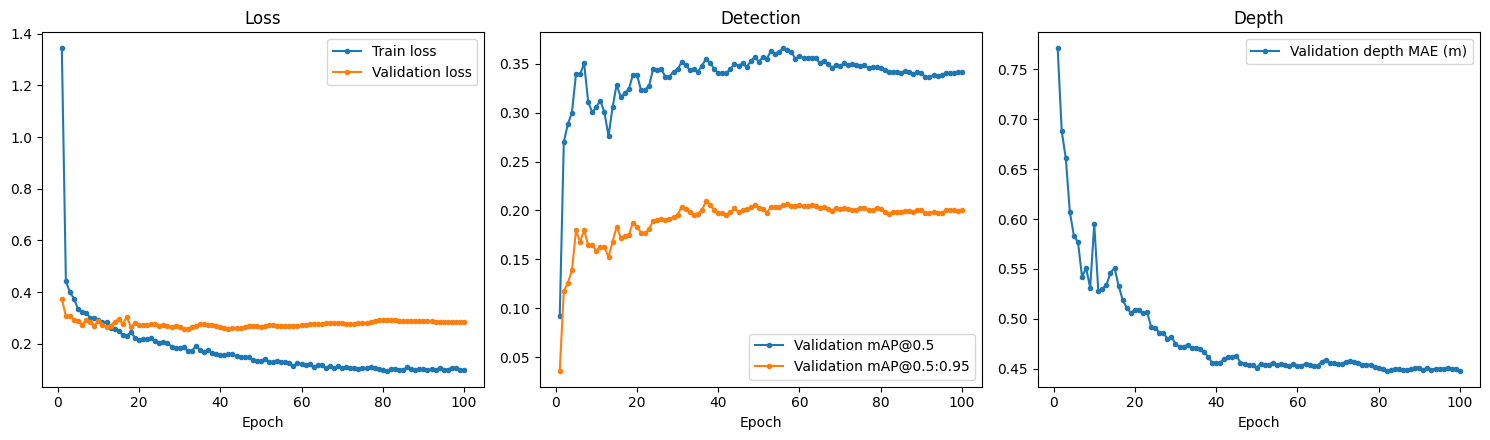

Saved training curves: C:\Users\ACER\Downloads\Comvis\code\training_runs\persist\rtx4050_arsitektur_70_20_10\training_curves_20261023_114103.png


In [24]:
import csv
import datetime
import math
import matplotlib.pyplot as plt

if not HISTORY_CSV.is_file():
    print("Belum ada history.csv. Jalankan training terlebih dahulu untuk membuat grafik.")
else:
    with HISTORY_CSV.open("r", newline="", encoding="utf-8") as history_file:
        history_rows = list(csv.DictReader(history_file))
    history_rows = [row for row in history_rows if row.get("epoch")]
    if not history_rows:
        print("history.csv belum berisi metrik epoch.")
    else:
        epochs = [int(row["epoch"]) for row in history_rows]
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
        for key, label in (("train_loss", "Train loss"), ("val_loss", "Validation loss")):
            values = [float(row[key]) if row.get(key) else math.nan for row in history_rows]
            axes[0].plot(epochs, values, marker=".", label=label)
        axes[0].set_title("Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].legend()
        for key, label in (("val_map50", "Validation mAP@0.5"), ("val_map50_95", "Validation mAP@0.5:0.95")):
            values = [float(row[key]) if row.get(key) else math.nan for row in history_rows]
            axes[1].plot(epochs, values, marker=".", label=label)
        axes[1].set_title("Detection")
        axes[1].set_xlabel("Epoch")
        axes[1].legend()
        depth_mae = [float(row["val_depth_mae_m"]) if row.get("val_depth_mae_m") else math.nan for row in history_rows]
        axes[2].plot(epochs, depth_mae, marker=".", label="Validation depth MAE (m)")
        axes[2].set_title("Depth")
        axes[2].set_xlabel("Epoch")
        axes[2].legend()
        fig.tight_layout()
        plot_path = RUN_DIR / f"training_curves_{datetime.datetime.now():%Y%m%d_%H%M%S}.png"
        fig.savefig(plot_path, dpi=160)
        plt.show()
        plt.close(fig)
        print("Saved training curves:", plot_path)